# NLP Sentiment Classification on Customer Reviews (TF-IDF)
**Goal:** Build a text classifier that labels customer reviews as **positive** or **negative**. The notebook cleans and tokenizes raw text (lowercasing, HTML/punctuation removal, stopword removal, lemmatization), converts it into TF-IDF feature matrices, trains **Multinomial Naive Bayes** and **Logistic Regression**, benchmarks them, and ends with a `predict_sentiment()` helper for live custom phrases.

**Pipeline:**
1. Load the review dataset and detect the text/label columns
2. Exploratory analysis (class balance, review lengths)
3. Text preprocessing (HTML removal, lowercasing, contraction handling, stopword removal, lemmatization)
4. Stratified 80/20 train/test split
5. `TfidfVectorizer(max_features=5000)` fitted on the training text only
6. Train `MultinomialNB` and `LogisticRegression`
7. Benchmark: accuracy, precision, recall, F1, ROC-AUC, confusion matrices, cross-validation
8. Model interpretation (most influential words) and error analysis
9. `predict_sentiment()` and an interactive test helper

In [1]:
!pip install nltk beautifulsoup4
import nltk

nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: C:\Users\eshap\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\eshap\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\eshap\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\eshap\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\eshap\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\eshap\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-

True

In [2]:
import warnings
warnings.filterwarnings("ignore")

import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, confusion_matrix, roc_curve)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

## 1. Load the dataset

In [3]:
URL = "https://www.datheon.in/datasets/sentiment_reviews.csv"

try:
    raw = pd.read_csv(URL)
    print("Loaded the dataset from the Datheon URL.")
except Exception as e:
    # Fallback: a copy of the file saved next to this notebook as sentiment_reviews.csv
    raw = pd.read_csv("sentiment_reviews.csv")
    print("Could not download, loaded the local sentiment_reviews.csv instead.")

print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
raw.head()

Loaded the dataset from the Datheon URL.
Shape: (10, 3)
Columns: ['review_id', 'review_text', 'sentiment']


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative


### Detect the text and label columns
Column names can differ between dataset versions, so they are detected automatically. **If the detection picks the wrong columns, set `TEXT_COL` and `LABEL_COL` manually in the next cell.**

In [4]:
TEXT_COL = None    # e.g. "review"
LABEL_COL = None   # e.g. "sentiment"

text_names = ["review", "review_text", "reviewtext", "text", "content", "comment", "sentence", "body"]
label_names = ["sentiment", "label", "polarity", "rating", "stars", "score", "target", "class"]
lower_map = {c.lower(): c for c in raw.columns}

if TEXT_COL is None:
    TEXT_COL = next((lower_map[n] for n in text_names if n in lower_map), None)
if LABEL_COL is None:
    LABEL_COL = next((lower_map[n] for n in label_names if n in lower_map), None)

# Fallbacks: longest-text object column is the text; another column is the label
if TEXT_COL is None:
    obj_cols = raw.select_dtypes(include="object").columns
    TEXT_COL = max(obj_cols, key=lambda c: raw[c].astype(str).str.len().mean())
if LABEL_COL is None:
    LABEL_COL = next(c for c in raw.columns if c != TEXT_COL)

print(f"Text column : {TEXT_COL!r}")
print(f"Label column: {LABEL_COL!r}")
print("Raw label values:", raw[LABEL_COL].value_counts(dropna=False).head(10).to_dict())

Text column : 'review_text'
Label column: 'sentiment'
Raw label values: {'positive': 5, 'negative': 4, 'neutral': 1}


In [5]:
def to_binary(series):
    """Convert labels to 1 = positive, 0 = negative (NaN for neutral/unknown rows)."""
    s = series.copy()
    if s.dtype == object or str(s.dtype).startswith("str"):
        low = s.astype(str).str.strip().str.lower()
        mapped = low.map(lambda v: 1.0 if v.startswith("pos") else (0.0 if v.startswith("neg") else np.nan))
        if mapped.notna().mean() > 0.5:
            return mapped
        s = pd.to_numeric(low, errors="coerce")          # maybe numeric stored as text
    uniq = sorted(s.dropna().unique())
    if len(uniq) == 2:                                    # already binary (e.g. 0/1)
        return (s == uniq[-1]).astype(float).where(s.notna())
    lo, hi = uniq[0], uniq[-1]                            # rating scale: keep clear positives/negatives
    pos = s >= hi - 0.25 * (hi - lo)
    neg = s <= lo + 0.25 * (hi - lo)
    return pd.Series(np.where(pos, 1.0, np.where(neg, 0.0, np.nan)), index=s.index)

df = raw[[TEXT_COL, LABEL_COL]].copy()
df.columns = ["text", "raw_label"]
df["label"] = to_binary(df["raw_label"])

print("Rows before cleaning:", len(df))
df = df.dropna(subset=["text", "label"]).drop_duplicates(subset="text").reset_index(drop=True)
df["label"] = df["label"].astype(int)
print("Rows after dropping missing/neutral/duplicate reviews:", len(df))
df[["text", "raw_label", "label"]].head()

Rows before cleaning: 10
Rows after dropping missing/neutral/duplicate reviews: 9


,text,raw_label,label
0,"The product quality is exceptional, exceeded a...",positive,1
1,Terrible customer service and the item arrived...,negative,0
2,"Absolutely love this! Easy to setup, robust, a...",positive,1
3,Stopped working after two days. Extremely disa...,negative,0
4,Customer support helped resolve my setup quest...,positive,1


## 2. Exploratory analysis

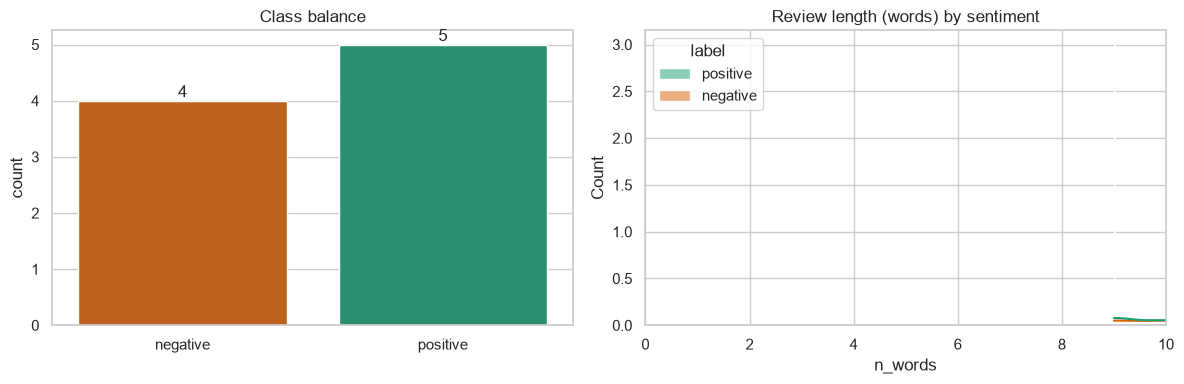

label
positive    0.556
negative    0.444
Name: proportion, dtype: float64


In [6]:
df["n_words"] = df["text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=df["label"].map({0: "negative", 1: "positive"}), ax=axes[0],
              order=["negative", "positive"], palette=["#d95f02", "#1b9e77"])
axes[0].set_title("Class balance")
axes[0].set_xlabel("")
for c in axes[0].containers:
    axes[0].bar_label(c)
sns.histplot(data=df, x="n_words", hue=df["label"].map({0: "negative", 1: "positive"}),
             bins=40, kde=True, ax=axes[1], palette={"negative": "#d95f02", "positive": "#1b9e77"})
axes[1].set_title("Review length (words) by sentiment")
axes[1].set_xlim(0, df["n_words"].quantile(0.99))
plt.tight_layout()
plt.show()
print(df["label"].value_counts(normalize=True).rename({0: "negative", 1: "positive"}).round(3))

## 3. Text preprocessing
Steps applied to every review:
1. Unescape HTML entities and remove HTML tags and URLs
2. Lowercase
3. Expand contractions (`don't` becomes `do not`) so negations survive tokenization
4. Remove punctuation and digits
5. Remove stopwords, **but keep negation words** such as *not*, *no*, *never*, because "not good" and "good" mean opposite things
6. Lemmatize (`movies` becomes `movie`, `loved` becomes `love`)

NLTK's stopword list and WordNet lemmatizer are used when available. If they cannot be downloaded, the notebook falls back to scikit-learn's stopword list and a simple plural-stripping lemmatizer so it still runs.

In [7]:
NEGATIONS = {"no", "nor", "not", "never", "neither", "cannot", "none", "nothing", "nowhere", "hardly"}

try:
    import nltk
    for pkg in ["stopwords", "wordnet", "omw-1.4"]:
        nltk.download(pkg, quiet=True)
    from nltk.corpus import stopwords
    from nltk.stem import WordNetLemmatizer
    _wn = WordNetLemmatizer()
    _wn.lemmatize("tests")                      # raises LookupError if WordNet data is missing
    STOP = set(stopwords.words("english")) - NEGATIONS
    def lemmatize(word):
        return _wn.lemmatize(_wn.lemmatize(word, "v"), "n")   # verb form first, then noun form
    BACKEND = "NLTK (WordNet lemmatizer + NLTK stopwords)"
except Exception:
    STOP = set(ENGLISH_STOP_WORDS) - NEGATIONS
    def lemmatize(word):                        # crude plural stripping fallback
        if len(word) > 4 and word.endswith("ies"):
            return word[:-3] + "y"
        if len(word) > 4 and word.endswith("sses"):
            return word[:-2]
        if len(word) > 3 and word.endswith("s") and not word.endswith(("ss", "us", "is")):
            return word[:-1]
        return word
    BACKEND = "fallback (scikit-learn stopwords + simple plural stripping)"

print("Preprocessing backend:", BACKEND)

CONTRACTIONS = [(r"won't", "will not"), (r"can't", "can not"), (r"n't", " not"), (r"'re", " are"),
                (r"'ve", " have"), (r"'ll", " will"), (r"'m", " am"), (r"'d", " would")]

def clean_text(text):
    text = html.unescape(str(text)).lower().replace("\u2019", "'")
    text = re.sub(r"<[^>]+>", " ", text)                  # HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)         # URLs
    for pattern, repl in CONTRACTIONS:
        text = re.sub(pattern, repl, text)
    text = re.sub(r"[^a-z\s]", " ", text)                 # punctuation, digits
    tokens = [t for t in text.split() if len(t) > 1 and t not in STOP]
    return " ".join(lemmatize(t) for t in tokens)

examples = ["<br />I LOVED this movie!! Best acting I've seen in years :)",
            "It wasn't good. Don't waste your money on these terrible products."]
for e in examples:
    print("RAW  :", e)
    print("CLEAN:", clean_text(e), "\n")

Preprocessing backend: NLTK (WordNet lemmatizer + NLTK stopwords)
RAW  : <br />I LOVED this movie!! Best acting I've seen in years :)
CLEAN: love movie best act see year 

RAW  : It wasn't good. Don't waste your money on these terrible products.
CLEAN: not good not waste money terrible product 



In [8]:
df["clean_text"] = df["text"].apply(clean_text)
df = df[df["clean_text"].str.strip() != ""].reset_index(drop=True)   # drop reviews that became empty
print("Reviews kept:", len(df))
df[["text", "clean_text", "label"]].head()

Reviews kept: 9


,text,clean_text,label
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceed expectation,1
1,Terrible customer service and the item arrived...,terrible customer service item arrive complete...,0
2,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,1
3,Stopped working after two days. Extremely disa...,stop work two day extremely disappoint purchase,0
4,Customer support helped resolve my setup quest...,customer support help resolve setup question w...,1


## 4. Train/test split (80/20, stratified)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"], test_size=0.20, random_state=RANDOM_STATE, stratify=df["label"])
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print("Train positive rate:", round(y_train.mean(), 3), "| Test positive rate:", round(y_test.mean(), 3))

Train: 7 | Test: 2
Train positive rate: 0.571 | Test positive rate: 0.5


## 5. TF-IDF feature extraction
`TfidfVectorizer(max_features=5000)` keeps the 5,000 most frequent terms. Unigrams and bigrams are used (`ngram_range=(1, 2)`) so that short phrases like *not good* become features. The vectorizer is **fitted on the training text only**.

In [10]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF matrix (train):", X_train_tfidf.shape, "| sparsity:",
      f"{1 - X_train_tfidf.nnz / np.prod(X_train_tfidf.shape):.2%}")
vocab = np.array(tfidf.get_feature_names_out())
print("Sample features:", list(vocab[:15]))

TF-IDF matrix (train): (7, 2) | sparsity: 71.43%
Sample features: ['purchase', 'work']


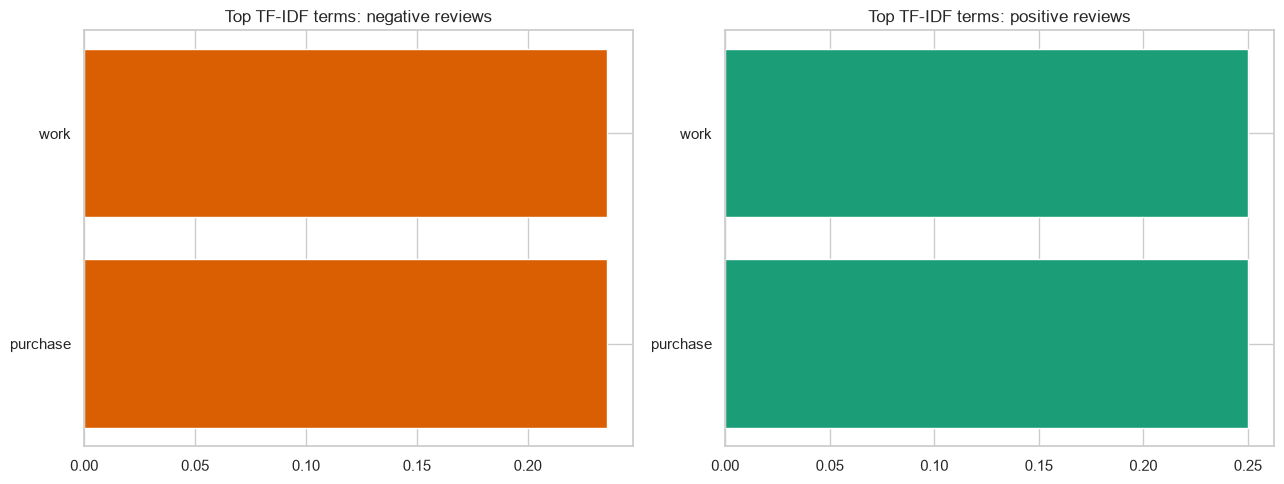

In [11]:
# Highest average TF-IDF weight per class (what each class talks about most)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (cls, name, color) in zip(axes, [(0, "negative", "#d95f02"), (1, "positive", "#1b9e77")]):
    mask = (y_train.values == cls)
    mean_w = np.asarray(X_train_tfidf[mask].mean(axis=0)).ravel()
    top = np.argsort(mean_w)[-15:]
    ax.barh(vocab[top], mean_w[top], color=color)
    ax.set_title(f"Top TF-IDF terms: {name} reviews")
plt.tight_layout()
plt.show()

## 6. Train the models

In [12]:
nb = MultinomialNB(alpha=1.0).fit(X_train_tfidf, y_train)
lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_tfidf, y_train)
models = {"Multinomial Naive Bayes": nb, "Logistic Regression": lr}
print("Both models trained.")

Both models trained.


## 7. Evaluation

In [13]:
rows, preds, probas = [], {}, {}
for name, m in models.items():
    p = m.predict(X_test_tfidf)
    pr = m.predict_proba(X_test_tfidf)[:, 1]
    preds[name], probas[name] = p, pr
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p),
                 "ROC-AUC": roc_auc_score(y_test, pr)})
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Multinomial Naive Bayes,0.5,0.5,1.0,0.6667,0.5
Logistic Regression,0.5,0.5,1.0,0.6667,0.5


In [14]:
for name, p in preds.items():
    print("=" * 60); print(name); print("=" * 60)
    print(classification_report(y_test, p, target_names=["negative", "positive"], digits=3))

Multinomial Naive Bayes
              precision    recall  f1-score   support

    negative      0.000     0.000     0.000         1
    positive      0.500     1.000     0.667         1

    accuracy                          0.500         2
   macro avg      0.250     0.500     0.333         2
weighted avg      0.250     0.500     0.333         2

Logistic Regression
              precision    recall  f1-score   support

    negative      0.000     0.000     0.000         1
    positive      0.500     1.000     0.667         1

    accuracy                          0.500         2
   macro avg      0.250     0.500     0.333         2
weighted avg      0.250     0.500     0.333         2



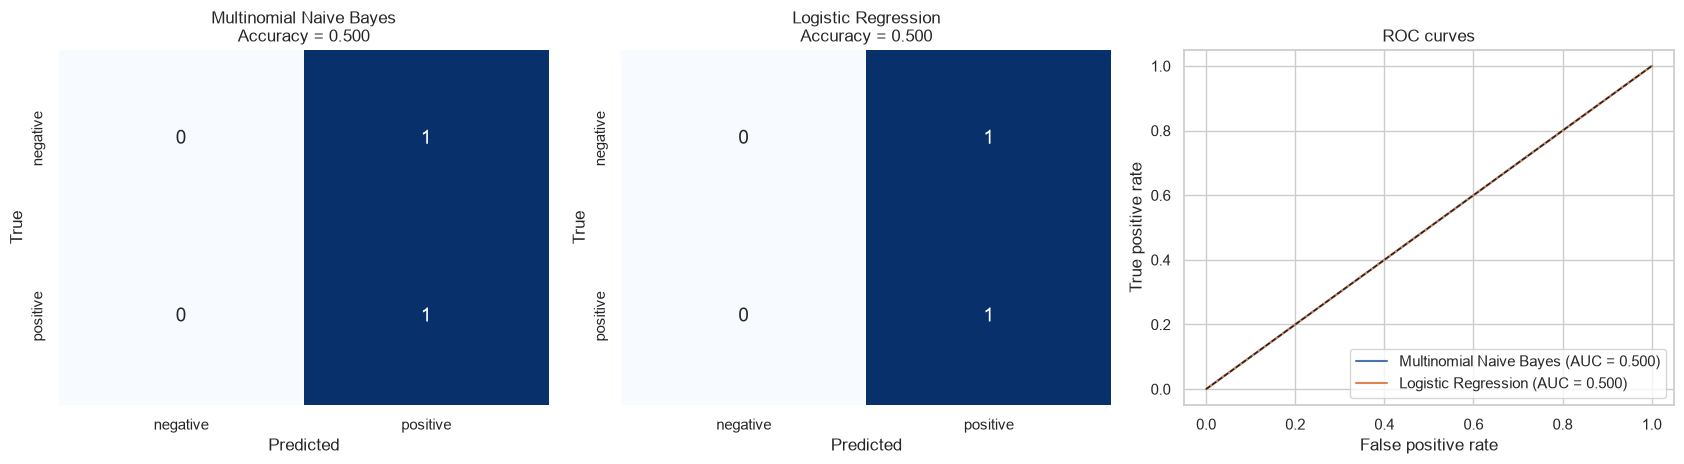

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (name, p) in zip(axes[:2], preds.items()):
    cm = confusion_matrix(y_test, p)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 14},
                xticklabels=["negative", "positive"], yticklabels=["negative", "positive"], ax=ax)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, p):.3f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for name, pr in probas.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    axes[2].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, pr):.3f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=1)
axes[2].set_title("ROC curves"); axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
axes[2].legend(loc="lower right")
plt.tight_layout()
plt.show()

### Cross-validation and light hyperparameter tuning
The vectorizer is placed **inside** a `Pipeline`, so each CV fold fits TF-IDF only on that fold's training part, with no leakage. A small grid search then tunes the smoothing strength of Naive Bayes (`alpha`) and the regularization of Logistic Regression (`C`).

In [16]:
min_class_size = y_train.value_counts().min()
n_splits = min(5, min_class_size)

if n_splits < 2:
    raise ValueError("Not enough samples per class for cross-validation.")

cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
def make_pipe(clf):
    return Pipeline([("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)), ("clf", clf)])

cv_rows = []
for name, clf in [("Multinomial Naive Bayes", MultinomialNB()),
                  ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]:
    scores = cross_val_score(make_pipe(clf), X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    cv_rows.append({"Model": name, "CV accuracy (mean)": scores.mean(), "CV accuracy (std)": scores.std()})
cv_results = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_results

,CV accuracy (mean),CV accuracy (std)
Model,,
Multinomial Naive Bayes,NaN,NaN
Logistic Regression,NaN,NaN


In [17]:
grids = {
    "Multinomial Naive Bayes": (make_pipe(MultinomialNB()), {"clf__alpha": [0.1, 0.3, 0.5, 1.0, 2.0]}),
    "Logistic Regression": (make_pipe(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                            {"clf__C": [0.1, 0.5, 1, 5, 10, 50]}),
}
tuned, tuned_rows = {}, []
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    p = gs.predict(X_test)
    tuned_rows.append({"Model": name + " (tuned)", "Best params": gs.best_params_,
                       "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
                       "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p)})
tuned_results = pd.DataFrame(tuned_rows).set_index("Model")
tuned_results.round(4)

,Best params,Accuracy,Precision,Recall,F1
Model,,,,,
Multinomial Naive Bayes (tuned),{'clf__alpha': 0.1},0.5,0.5,1.0,0.6667
Logistic Regression (tuned),{'clf__C': 0.1},0.5,0.5,1.0,0.6667


,Accuracy,Precision,Recall,F1
Model,,,,
Multinomial Naive Bayes,0.5,0.5,1.0,0.6667
Logistic Regression,0.5,0.5,1.0,0.6667
Multinomial Naive Bayes (tuned),0.5,0.5,1.0,0.6667
Logistic Regression (tuned),0.5,0.5,1.0,0.6667


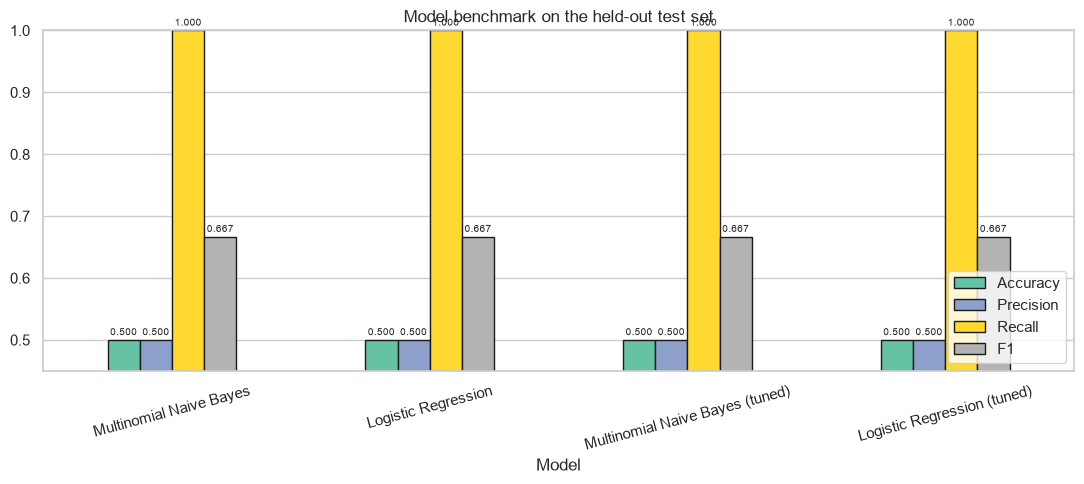

In [18]:
summary = pd.concat([results.drop(columns="ROC-AUC"),
                     tuned_results.drop(columns="Best params")]).round(4)
display(summary)

ax = summary[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(11, 5), rot=15,
                                                              colormap="Set2", edgecolor="k")
lo = max(0, summary[["Accuracy", "Precision", "Recall", "F1"]].min().min() - 0.05)
ax.set_ylim(lo, 1.0)
ax.set_title("Model benchmark on the held-out test set")
ax.legend(loc="lower right")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", padding=2, fontsize=7)
plt.tight_layout()
plt.show()

## 8. Interpretation and error analysis

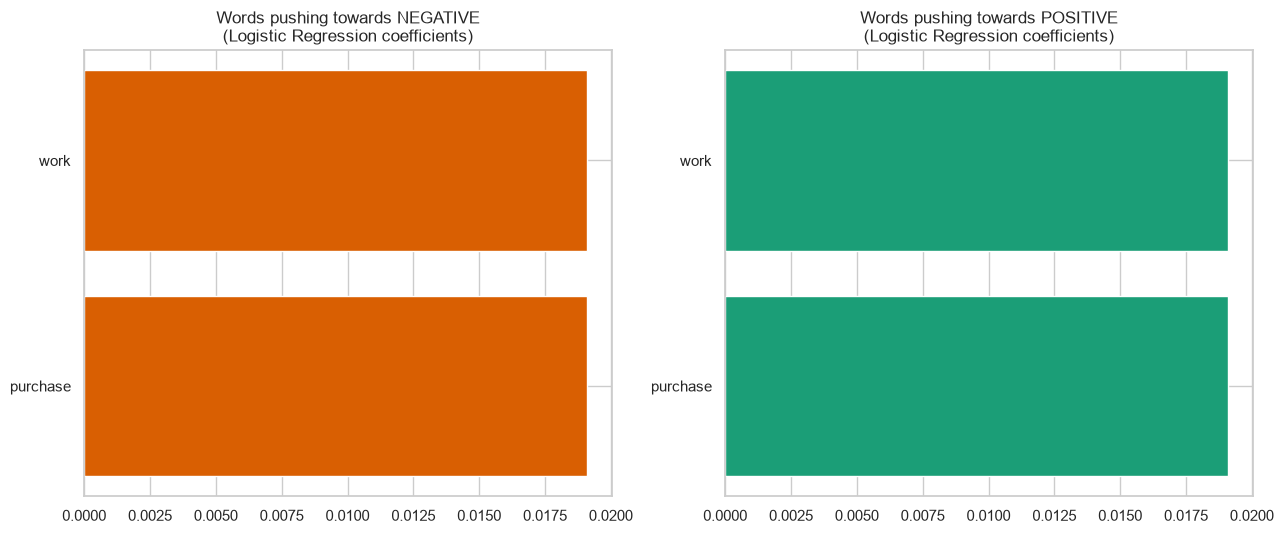

In [19]:
coef = lr.coef_[0]
order = np.argsort(coef)
top_neg, top_pos = order[:15], order[-15:]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].barh(vocab[top_neg], coef[top_neg], color="#d95f02")
axes[0].set_title("Words pushing towards NEGATIVE\n(Logistic Regression coefficients)")
axes[1].barh(vocab[top_pos], coef[top_pos], color="#1b9e77")
axes[1].set_title("Words pushing towards POSITIVE\n(Logistic Regression coefficients)")
plt.tight_layout()
plt.show()

In [20]:
best_name = results["Accuracy"].idxmax()
errors = pd.DataFrame({"review": df.loc[X_test.index, "text"].values,
                       "true": y_test.map({0: "negative", 1: "positive"}).values,
                       "predicted": pd.Series(preds[best_name]).map({0: "negative", 1: "positive"}).values,
                       "P(positive)": probas[best_name]})
errors = errors[errors["true"] != errors["predicted"]]
print(f"{best_name}: {len(errors)} misclassified of {len(y_test)} test reviews. A few examples:")
pd.set_option("display.max_colwidth", 140)
errors.head(8)

Multinomial Naive Bayes: 1 misclassified of 2 test reviews. A few examples:


,review,true,predicted,P(positive)
0,Delivery was slow and package was missing one adapter cable.,negative,positive,0.571429


## 9. `predict_sentiment()`: test your own phrases
The helper applies the **same preprocessing and the same fitted TF-IDF vectorizer** to any new text, then returns the predicted label and the model's confidence. The best-performing model from the test-set benchmark is used by default.

In [21]:
best_name = "Logistic Regression"
best_model = models[best_name]

print("Default model for predict_sentiment():", best_name)

def predict_sentiment(text, model=None, verbose=True):
    """Classify a custom review. Returns (label, confidence)."""
    model = model or best_model
    cleaned = clean_text(text)
    if not cleaned:
        if verbose:
            print("No usable words left after preprocessing; try a longer phrase.")
        return None, None
    vec = tfidf.transform([cleaned])
    p_pos = model.predict_proba(vec)[0, 1]
    label = "positive" if p_pos >= 0.5 else "negative"
    confidence = p_pos if label == "positive" else 1 - p_pos
    if verbose:
        print(f"{label.upper():8s} ({confidence:.1%} confident)  <-  {text!r}")
    return label, confidence

samples = [
    "Absolutely loved it, would definitely buy again!",
    "This product is terrible and broke after two days.",
    "The movie was not good at all.",
    "Not bad, actually pretty great.",
    "Fantastic quality, fast delivery, very happy with the purchase.",
    "Worst customer service ever, I want a refund.",
]
for s in samples:
    predict_sentiment(s)

Default model for predict_sentiment(): Logistic Regression
POSITIVE (56.9% confident)  <-  'Absolutely loved it, would definitely buy again!'
POSITIVE (56.9% confident)  <-  'This product is terrible and broke after two days.'
POSITIVE (56.9% confident)  <-  'The movie was not good at all.'
POSITIVE (56.9% confident)  <-  'Not bad, actually pretty great.'
POSITIVE (57.4% confident)  <-  'Fantastic quality, fast delivery, very happy with the purchase.'
POSITIVE (56.9% confident)  <-  'Worst customer service ever, I want a refund.'


In [22]:
# Compare both models side by side on the same phrases
compare = []
for s in samples:
    row = {"phrase": s}
    for name, m in models.items():
        label, conf = predict_sentiment(s, model=m, verbose=False)
        row[name] = f"{label} ({conf:.0%})"
    compare.append(row)
pd.DataFrame(compare).set_index("phrase")

,Multinomial Naive Bayes,Logistic Regression
phrase,,
"Absolutely loved it, would definitely buy again!",positive (57%),positive (57%)
This product is terrible and broke after two days.,positive (57%),positive (57%)
The movie was not good at all.,positive (57%),positive (57%)
"Not bad, actually pretty great.",positive (57%),positive (57%)
"Fantastic quality, fast delivery, very happy with the purchase.",positive (57%),positive (57%)
"Worst customer service ever, I want a refund.",positive (57%),positive (57%)


### Interactive test helper
Run the next cell and type your own reviews. Press Enter on an empty line or type `quit` to stop. (The cell waits for input, so it is placed last.)

In [ ]:
def interactive_test(model=None):
    print("Type a review and press Enter. Type 'quit' (or press Enter on an empty line) to stop.\n")
    while True:
        try:
            text = input("Review> ")
        except (EOFError, KeyboardInterrupt):
            break
        if text.strip().lower() in {"", "quit", "exit", "q"}:
            print("Goodbye!")
            break
        predict_sentiment(text, model=model)

interactive_test()


Type a review and press Enter. Type 'quit' (or press Enter on an empty line) to stop.



## Conclusions
- **Preprocessing:** HTML tags, URLs, punctuation and digits were removed, text was lowercased and lemmatized, and stopwords were dropped **except negations**, which keeps phrases like "not good" meaningful. Bigram TF-IDF features help the models capture these short phrases.
- **Models:** Multinomial Naive Bayes is fast and a strong baseline for sparse TF-IDF text. Logistic Regression usually edges it out slightly and gives interpretable coefficients (section 8). Check the benchmark tables above for the exact numbers from your run.
- **Evaluation:** Accuracy, precision, recall, F1 and ROC-AUC are reported on a stratified held-out test set, backed by 5-fold cross-validation with the vectorizer inside the pipeline to prevent leakage.
- **Limitations:** Bag-of-words models ignore word order beyond bigrams, so sarcasm, mixed opinions and long-range negation can fool them. Neutral reviews are not modeled.
- **Next steps:** Try SVMs, character n-grams, word embeddings, or a fine-tuned transformer (e.g. DistilBERT) as stronger baselines.